In [49]:
# Install torch if not already installed
%pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.5/80.5 MB 2.5 MB/s  0:00:38m0:00:0100:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 4.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 3.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 4.8 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [torch]32m5/6 [torch]]x]

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [45]:
# Install statsmodels if not already installed
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 2.2 MB/s  0:00:04eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [52]:
import pandas as pd
import matplotlib.pyplot as pyplot
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
import numpy as np

In [3]:
df = pd.read_csv("dataset/lassa_fever_timeseries_full.csv")

In [4]:
df.head()

,week_start_date,week_end_date,epi_year,epi_week,suspected_cases,confirmed_cases,probable_cases,deaths,extraction_method,extraction_timestamp,report_pdf_url
0,2019-12-30,2020-01-05,2020,1,98,18,0,2,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
1,2020-01-06,2020-01-12,2020,2,158,64,0,12,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
2,2020-01-13,2020-01-19,2020,3,159,81,0,10,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
3,2020-01-20,2020-01-26,2020,4,318,95,3,19,automated,2025-12-01T01:08:42.783211,https://ncdc.gov.ng/themes/common/files/sitrep...
4,2020-01-27,2020-02-02,2020,5,531,104,0,6,automated,2025-12-01T01:08:43.217629,https://ncdc.gov.ng/themes/common/files/sitrep...


In [5]:
df.columns

Index(['week_start_date', 'week_end_date', 'epi_year', 'epi_week',
       'suspected_cases', 'confirmed_cases', 'probable_cases', 'deaths',
       'extraction_method', 'extraction_timestamp', 'report_pdf_url'],
      dtype='object')

In [6]:
df.dtypes

week_start_date         object
week_end_date           object
epi_year                 int64
epi_week                 int64
suspected_cases          int64
confirmed_cases          int64
probable_cases           int64
deaths                   int64
extraction_method       object
extraction_timestamp    object
report_pdf_url          object
dtype: object

In [7]:
df['week_start_date'] = pd.to_datetime(df['week_start_date'])
df['week_end_date'] = pd.to_datetime(df['week_end_date'])

In [8]:
df.dtypes

week_start_date         datetime64[ns]
week_end_date           datetime64[ns]
epi_year                         int64
epi_week                         int64
suspected_cases                  int64
confirmed_cases                  int64
probable_cases                   int64
deaths                           int64
extraction_method               object
extraction_timestamp            object
report_pdf_url                  object
dtype: object

In [9]:
df.head()

,week_start_date,week_end_date,epi_year,epi_week,suspected_cases,confirmed_cases,probable_cases,deaths,extraction_method,extraction_timestamp,report_pdf_url
0,2019-12-30,2020-01-05,2020,1,98,18,0,2,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
1,2020-01-06,2020-01-12,2020,2,158,64,0,12,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
2,2020-01-13,2020-01-19,2020,3,159,81,0,10,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
3,2020-01-20,2020-01-26,2020,4,318,95,3,19,automated,2025-12-01T01:08:42.783211,https://ncdc.gov.ng/themes/common/files/sitrep...
4,2020-01-27,2020-02-02,2020,5,531,104,0,6,automated,2025-12-01T01:08:43.217629,https://ncdc.gov.ng/themes/common/files/sitrep...


In [10]:
# 1.2 Sorting the data by time
df = df.sort_values('week_start_date').reset_index(drop=True)

In [11]:
df.head()

,week_start_date,week_end_date,epi_year,epi_week,suspected_cases,confirmed_cases,probable_cases,deaths,extraction_method,extraction_timestamp,report_pdf_url
0,2019-12-30,2020-01-05,2020,1,98,18,0,2,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
1,2020-01-06,2020-01-12,2020,2,158,64,0,12,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
2,2020-01-13,2020-01-19,2020,3,159,81,0,10,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...
3,2020-01-20,2020-01-26,2020,4,318,95,3,19,automated,2025-12-01T01:08:42.783211,https://ncdc.gov.ng/themes/common/files/sitrep...
4,2020-01-27,2020-02-02,2020,5,531,104,0,6,automated,2025-12-01T01:08:43.217629,https://ncdc.gov.ng/themes/common/files/sitrep...


In [12]:
# 4. Generate the 'Perfect Calendar'
# We create a range from the first date to the last date with a weekly frequency (W-MON for Mondays)
start_date = df['week_start_date'].min()
end_date = df['week_start_date'].max()
expected_range = pd.date_range(start=start_date, end=end_date, freq='W-MON')

# 5. Find the difference
# This looks for any dates in the 'expected_range' that are NOT in our dataframe
missing_weeks = expected_range.difference(df['week_start_date'])

# 6. Output the results
print(f"Analysis Period: {start_date.date()} to {end_date.date()}")
print(f"Total weeks expected: {len(expected_range)}")
print(f"Total weeks present: {len(df)}")
print(f"Missing weeks found: {len(missing_weeks)}")

if len(missing_weeks) > 0:
    print("\nWarning! The following weeks are missing:")
    for week in missing_weeks:
        print(week.date())
else:
    print("\nData Integrity Verified: The timeseries is 100% continuous.")

Analysis Period: 2019-12-30 to 2025-12-22
Total weeks expected: 313
Total weeks present: 313
Missing weeks found: 0

Data Integrity Verified: The timeseries is 100% continuous.


In [13]:
# 1.3 Feature Engineering: Case Fatality Rate (CFR) and Positivity Rate
# We use .fillna(0) to handle weeks where there were 0 cases (to avoid division by zero errors)
df['cfr_percent'] = (df['deaths'] / df['confirmed_cases']).fillna(0) * 100
df['positivity_rate'] = (df['confirmed_cases'] / df['suspected_cases']).fillna(0)

In [14]:
df.head()

,week_start_date,week_end_date,epi_year,epi_week,suspected_cases,confirmed_cases,probable_cases,deaths,extraction_method,extraction_timestamp,report_pdf_url,cfr_percent,positivity_rate
0,2019-12-30,2020-01-05,2020,1,98,18,0,2,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...,11.111111,0.183673
1,2020-01-06,2020-01-12,2020,2,158,64,0,12,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...,18.750000,0.405063
2,2020-01-13,2020-01-19,2020,3,159,81,0,10,manual,2025-12-01T02:00,https://ncdc.gov.ng/themes/common/files/sitrep...,12.345679,0.509434
3,2020-01-20,2020-01-26,2020,4,318,95,3,19,automated,2025-12-01T01:08:42.783211,https://ncdc.gov.ng/themes/common/files/sitrep...,20.000000,0.298742
4,2020-01-27,2020-02-02,2020,5,531,104,0,6,automated,2025-12-01T01:08:43.217629,https://ncdc.gov.ng/themes/common/files/sitrep...,5.769231,0.195857


In [16]:
total_suspected = df['suspected_cases'].sum()
total_suspected

np.int64(47814)

In [17]:
total_confirmed = df['confirmed_cases'].sum()
total_confirmed

np.int64(6456)

In [19]:
total_probable  = df['probable_cases'].sum()
total_probable

np.int64(53)

In [20]:
total_deaths    = df['deaths'].sum()
total_deaths

np.int64(1008)

In [21]:
# 3. Calculate Annual Totals (Breakdown by Year)
# This helps us see which year was the "hottest" for the outbreak
annual_summary = df.groupby('epi_year')[['suspected_cases', 'confirmed_cases', 'deaths']].sum()

# 4. Display the results
print("--- Overall Surveillance Totals (2020-2025) ---")
print(f"Total Suspected Cases: {total_suspected:,}")
print(f"Total Confirmed Cases: {total_confirmed:,}")
print(f"Total Probable Cases:  {total_probable:,}")
print(f"Total Deaths:          {total_deaths:,}")

print("\n--- Annual Breakdown ---")
print(annual_summary)

--- Overall Surveillance Totals (2020-2025) ---
Total Suspected Cases: 47,814
Total Confirmed Cases: 6,456
Total Probable Cases:  53
Total Deaths:          1,008

--- Annual Breakdown ---
          suspected_cases  confirmed_cases  deaths
epi_year                                          
2020                 6834             1190     159
2021                 4637              511      77
2022                 7984             1042     144
2023                 9124             1271     210
2024                10087             1311     207
2025                 9148             1131     211


In [22]:
# 5. Calculating the Overall Case Fatality Rate (CFR)
overall_cfr = (total_deaths / total_confirmed) * 100
print(f"\nOverall Case Fatality Rate: {overall_cfr:.2f}%")


Overall Case Fatality Rate: 15.61%


In [23]:
# --- STEP 2: SUMMARY STATISTICS ---
print("--- Dataset Summary ---")
print(df[['confirmed_cases', 'deaths', 'cfr_percent']].describe())

--- Dataset Summary ---
       confirmed_cases      deaths  cfr_percent
count       313.000000  313.000000   313.000000
mean         20.626198    3.220447    15.725017
std          25.664706    4.552327    15.997366
min           0.000000    0.000000     0.000000
25%           6.000000    0.000000     0.000000
50%          10.000000    1.000000    12.500000
75%          22.000000    4.000000    23.943662
max         137.000000   23.000000   100.000000


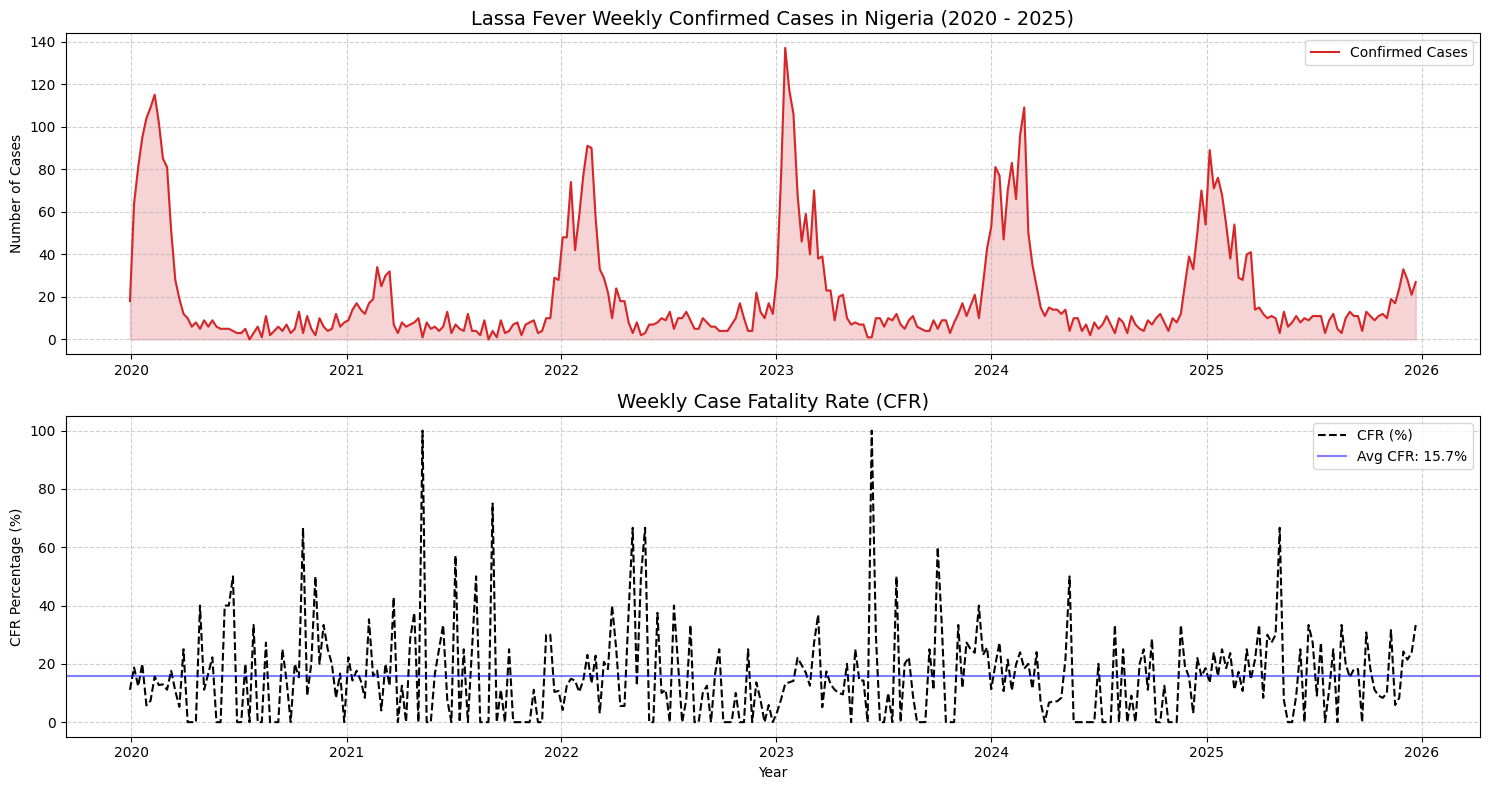

In [26]:
plt.figure(figsize=(15, 8))

# Plot 1: Confirmed Cases Trend
plt.subplot(2, 1, 1)
plt.plot(df['week_start_date'], df['confirmed_cases'], color='tab:red', label='Confirmed Cases')
plt.fill_between(df['week_start_date'], df['confirmed_cases'], color='tab:red', alpha=0.2)
plt.title('Lassa Fever Weekly Confirmed Cases in Nigeria (2020 - 2025)', fontsize=14)
plt.ylabel('Number of Cases')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Plot 2: Case Fatality Rate (CFR) Trend
plt.subplot(2, 1, 2)
plt.plot(df['week_start_date'], df['cfr_percent'], color='black', linestyle='--', label='CFR (%)')
plt.axhline(df['cfr_percent'].mean(), color='blue', alpha=0.5, label=f'Avg CFR: {df["cfr_percent"].mean():.1f}%')
plt.title('Weekly Case Fatality Rate (CFR)', fontsize=14)
plt.ylabel('CFR Percentage (%)')
plt.xlabel('Year')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

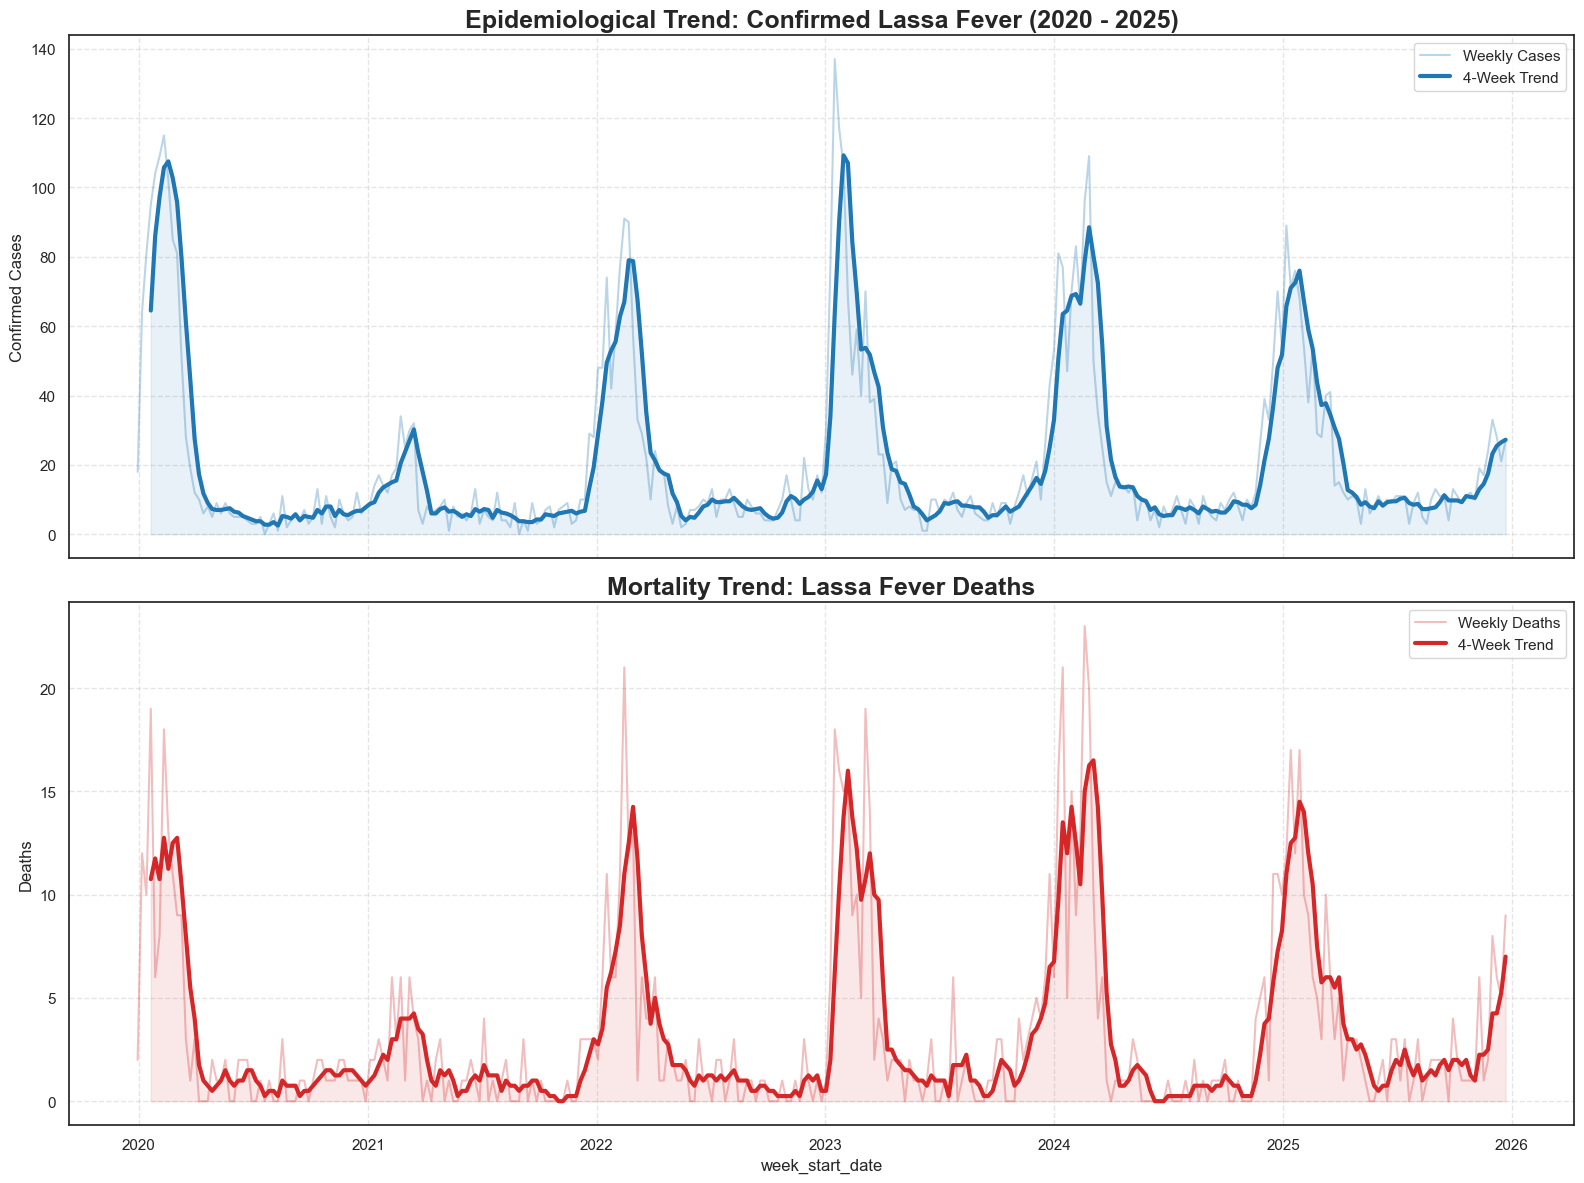


--- ANNUAL BURDEN OF DISEASE ---
          confirmed_cases  deaths
epi_year                         
2020                 1190     159
2021                  511      77
2022                 1042     144
2023                 1271     210
2024                 1311     207
2025                 1131     211


In [27]:
# 2. Style settings
sns.set_theme(style="white", palette="muted")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

# --- CHART 1: CONFIRMED CASES ---
# Plot raw data (faded) and the rolling trend (bold)
sns.lineplot(data=df, x='week_start_date', y='confirmed_cases', ax=ax1, color='tab:blue', alpha=0.3, label='Weekly Cases')
df['rolling_cases'] = df['confirmed_cases'].rolling(window=4).mean()
sns.lineplot(data=df, x='week_start_date', y='rolling_cases', ax=ax1, color='tab:blue', linewidth=3, label='4-Week Trend')

ax1.set_title('Epidemiological Trend: Confirmed Lassa Fever (2020 - 2025)', fontsize=18, fontweight='bold')
ax1.set_ylabel('Confirmed Cases', fontsize=12)
ax1.fill_between(df['week_start_date'], df['rolling_cases'], color='tab:blue', alpha=0.1)
ax1.grid(True, linestyle='--', alpha=0.5)

# --- CHART 2: DEATHS ---
sns.lineplot(data=df, x='week_start_date', y='deaths', ax=ax2, color='tab:red', alpha=0.3, label='Weekly Deaths')
df['rolling_deaths'] = df['deaths'].rolling(window=4).mean()
sns.lineplot(data=df, x='week_start_date', y='rolling_deaths', ax=ax2, color='tab:red', linewidth=3, label='4-Week Trend')

ax2.set_title('Mortality Trend: Lassa Fever Deaths', fontsize=18, fontweight='bold')
ax2.set_ylabel('Deaths', fontsize=12)
ax2.fill_between(df['week_start_date'], df['rolling_deaths'], color='tab:red', alpha=0.1)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Quick Table for Year-to-Year Insight
annual_stats = df.groupby('epi_year')[['confirmed_cases', 'deaths']].sum()
print("\n--- ANNUAL BURDEN OF DISEASE ---")
print(annual_stats)

/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/2238833671.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  annual_cfr = df.groupby('epi_year').apply(
/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/2238833671.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=annual_cfr, x='epi_year', y='avg_cfr', palette='rocket', ax=axes[0])


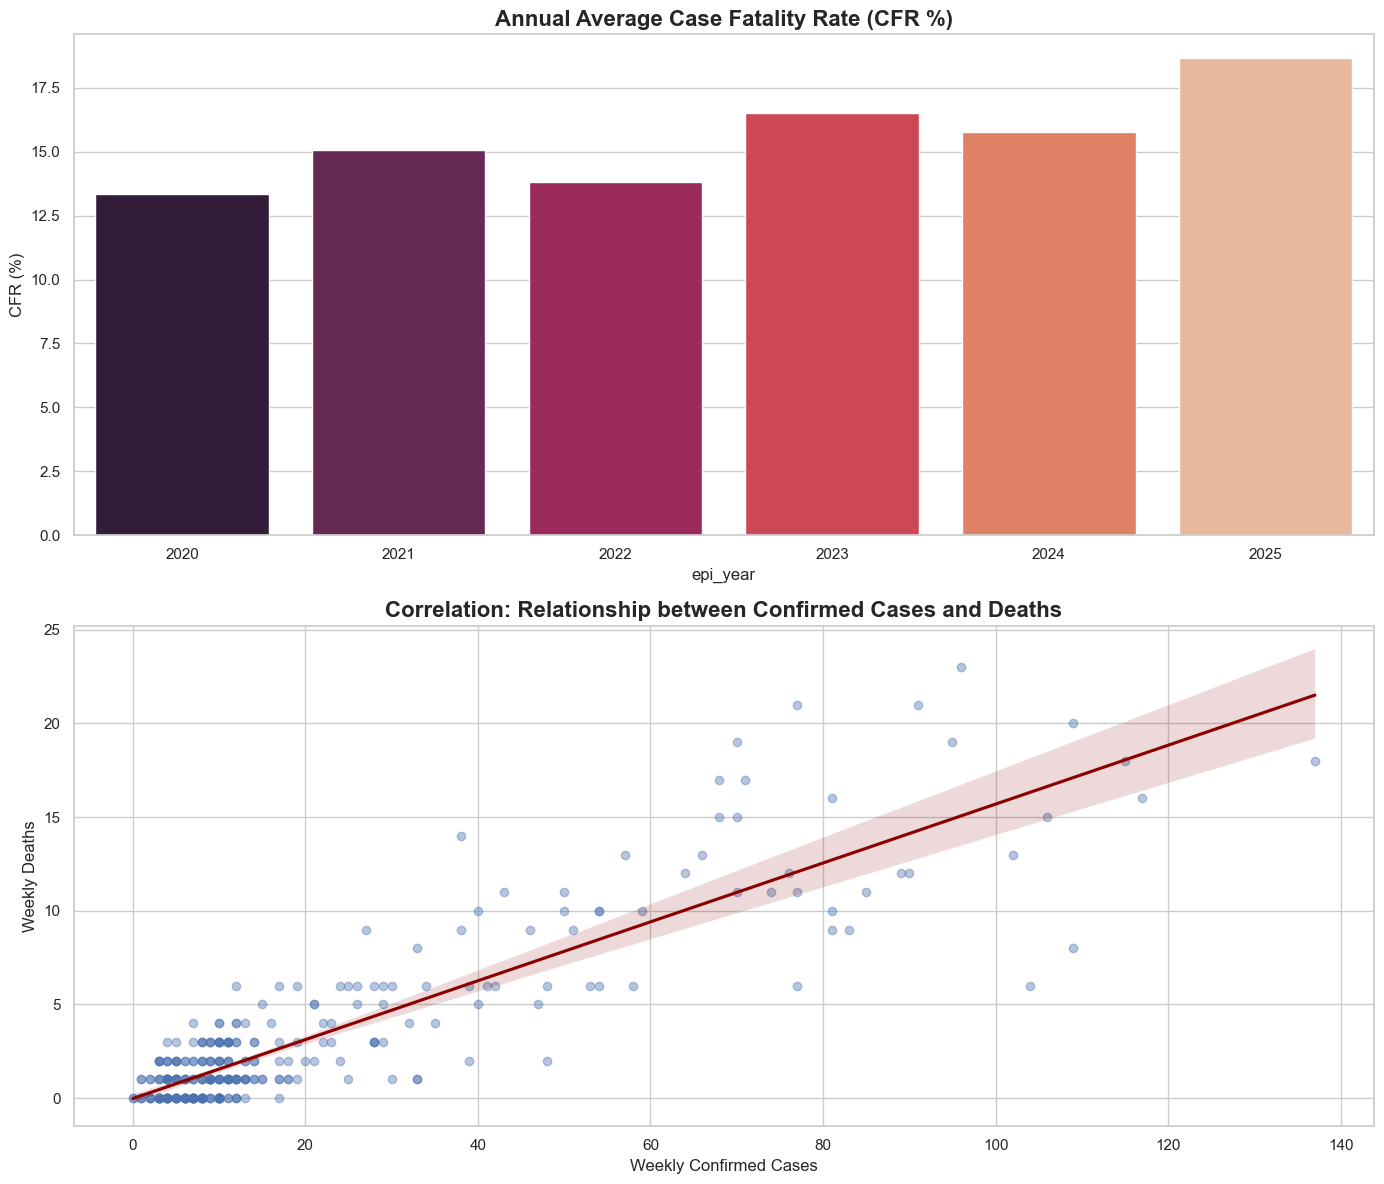

   epi_year    avg_cfr
0      2020  13.361345
1      2021  15.068493
2      2022  13.819578
3      2023  16.522423
4      2024  15.789474
5      2025  18.656057


In [28]:
# 2. Calculate Weekly CFR (%)
# We handle weeks with zero cases to avoid math errors
df['cfr_percent'] = (df['deaths'] / df['confirmed_cases']).fillna(0) * 100
df.loc[df['confirmed_cases'] == 0, 'cfr_percent'] = 0

# 3. Setup the Visuals
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- Plot A: Annual CFR Comparison ---
# Calculate average yearly CFR for the bar chart
annual_cfr = df.groupby('epi_year').apply(
    lambda x: (x['deaths'].sum() / x['confirmed_cases'].sum()) * 100
).reset_index(name='avg_cfr')

sns.barplot(data=annual_cfr, x='epi_year', y='avg_cfr', palette='rocket', ax=axes[0])
axes[0].set_title('Annual Average Case Fatality Rate (CFR %)', fontsize=16, fontweight='bold')
axes[0].set_ylabel('CFR (%)')

# --- Plot B: Cases vs Deaths (The Correlation) ---
sns.regplot(data=df, x='confirmed_cases', y='deaths', scatter_kws={'alpha':0.4}, 
            line_kws={'color':'darkred'}, ax=axes[1])
axes[1].set_title('Correlation: Relationship between Confirmed Cases and Deaths', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Weekly Confirmed Cases')
axes[1].set_ylabel('Weekly Deaths')

plt.tight_layout()
plt.show()

# Print the numbers for your report
print(annual_cfr)

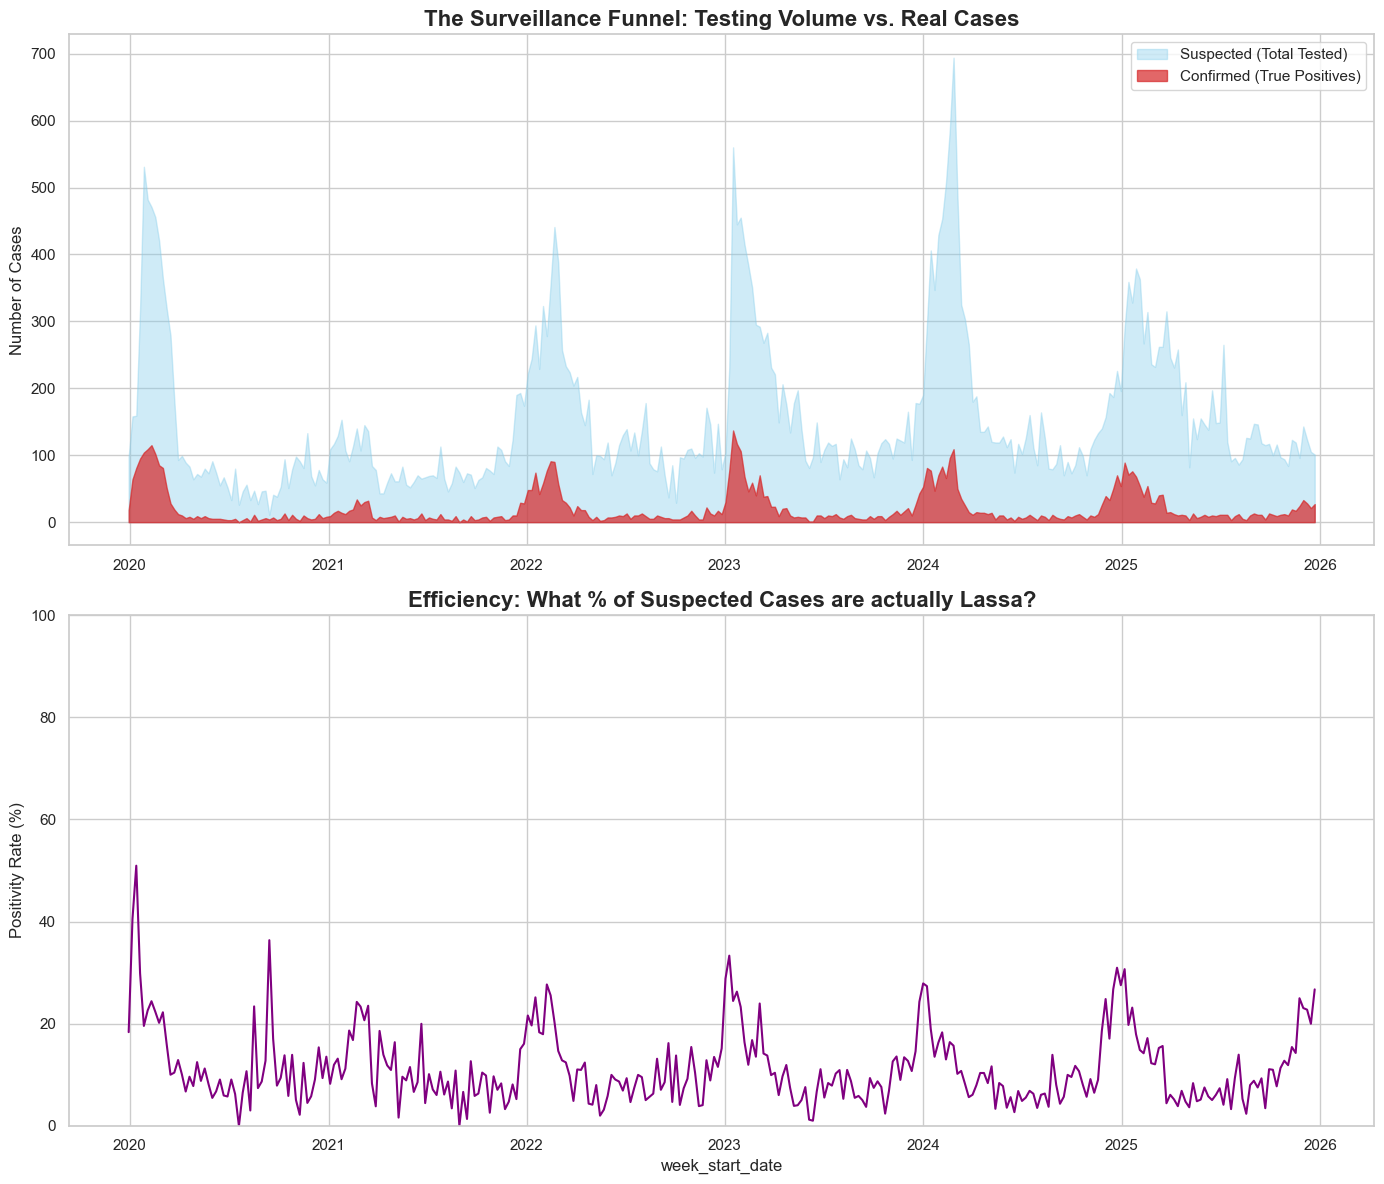

          suspected_cases  confirmed_cases  positivity_%
epi_year                                                
2020                 6834             1190     17.412935
2021                 4637              511     11.020056
2022                 7984             1042     13.051102
2023                 9124             1271     13.930294
2024                10087             1311     12.996927
2025                 9148             1131     12.363358


In [29]:
df['week_start_date'] = pd.to_datetime(df['week_start_date'])
df['positivity_rate'] = (df['confirmed_cases'] / df['suspected_cases']).fillna(0) * 100

# 2. Visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- Plot A: The Surveillance Funnel ---
axes[0].fill_between(df['week_start_date'], df['suspected_cases'], color="skyblue", alpha=0.4, label='Suspected (Total Tested)')
axes[0].fill_between(df['week_start_date'], df['confirmed_cases'], color="tab:red", alpha=0.7, label='Confirmed (True Positives)')
axes[0].set_title('The Surveillance Funnel: Testing Volume vs. Real Cases', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Number of Cases')
axes[0].legend()

# --- Plot B: Positivity Rate Trend ---
sns.lineplot(data=df, x='week_start_date', y='positivity_rate', ax=axes[1], color='purple')
axes[1].set_title('Efficiency: What % of Suspected Cases are actually Lassa?', fontsize=16, fontweight='bold')
axes[1].set_ylabel('Positivity Rate (%)')
axes[1].set_ylim(0, 100) # Percentage scale

plt.tight_layout()
plt.show()

# Print the Annual Efficiency Table
annual_summary = df.groupby('epi_year').agg({'suspected_cases':'sum', 'confirmed_cases':'sum'})
annual_summary['positivity_%'] = (annual_summary['confirmed_cases'] / annual_summary['suspected_cases']) * 100
print(annual_summary)

/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/3602599443.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=seasonal_avg, x='epi_week', y='confirmed_cases', palette='YlOrRd')


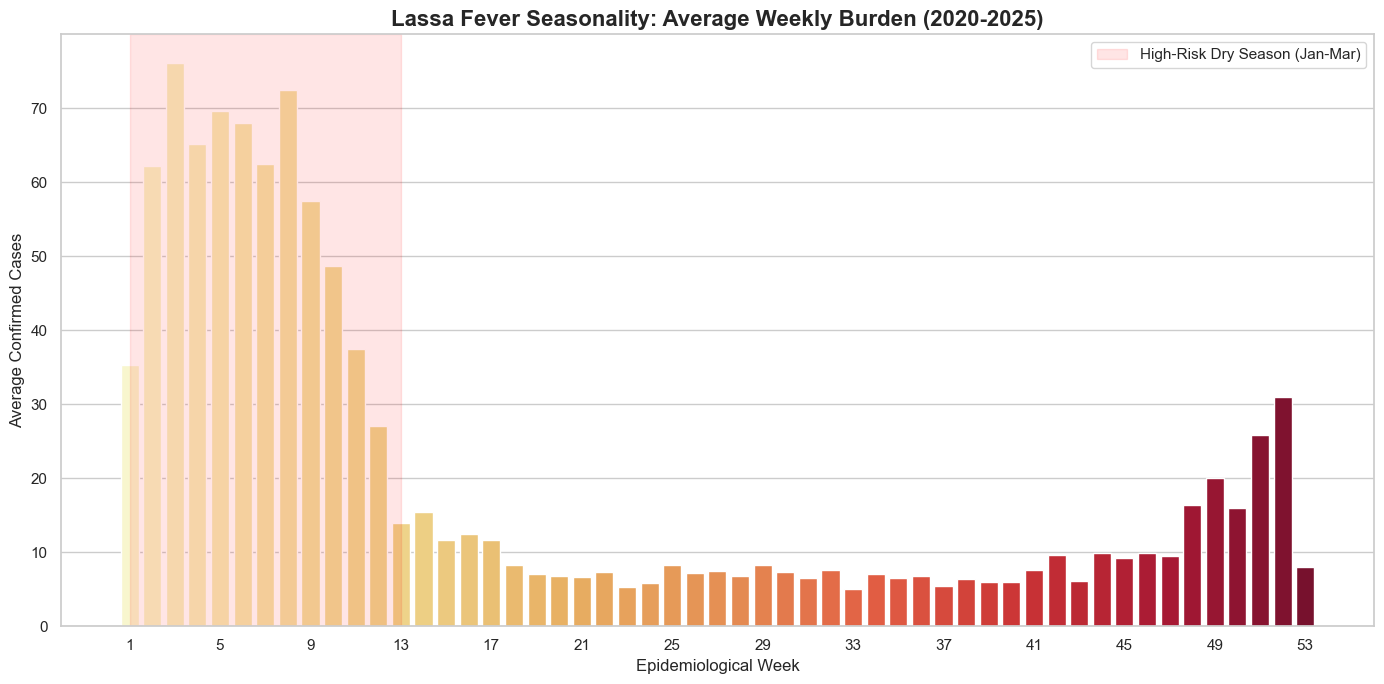

In [30]:
# 2. Calculate average cases per week across all years
seasonal_avg = df.groupby('epi_week')['confirmed_cases'].mean().reset_index()

# 3. Create the Seasonality Chart
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Bar chart showing the seasonal "hill"
sns.barplot(data=seasonal_avg, x='epi_week', y='confirmed_cases', palette='YlOrRd')

# Adding context: Highlighting the high-risk period
plt.axvspan(0, 12, color='red', alpha=0.1, label='High-Risk Dry Season (Jan-Mar)')

plt.title('Lassa Fever Seasonality: Average Weekly Burden (2020-2025)', fontsize=16, fontweight='bold')
plt.xlabel('Epidemiological Week', fontsize=12)
plt.ylabel('Average Confirmed Cases', fontsize=12)
plt.legend()

# Adjust ticks for clarity
plt.xticks(ticks=range(0, 53, 4), labels=range(1, 54, 4))
plt.tight_layout()
plt.show()

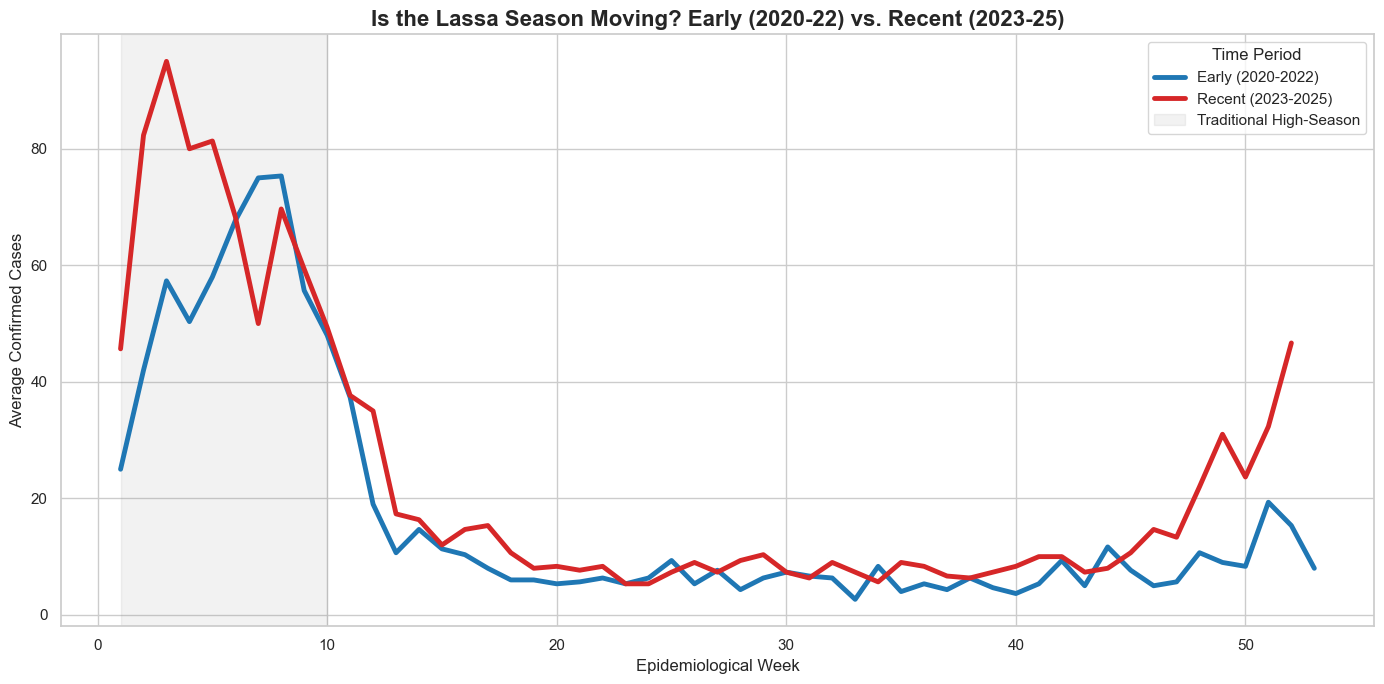

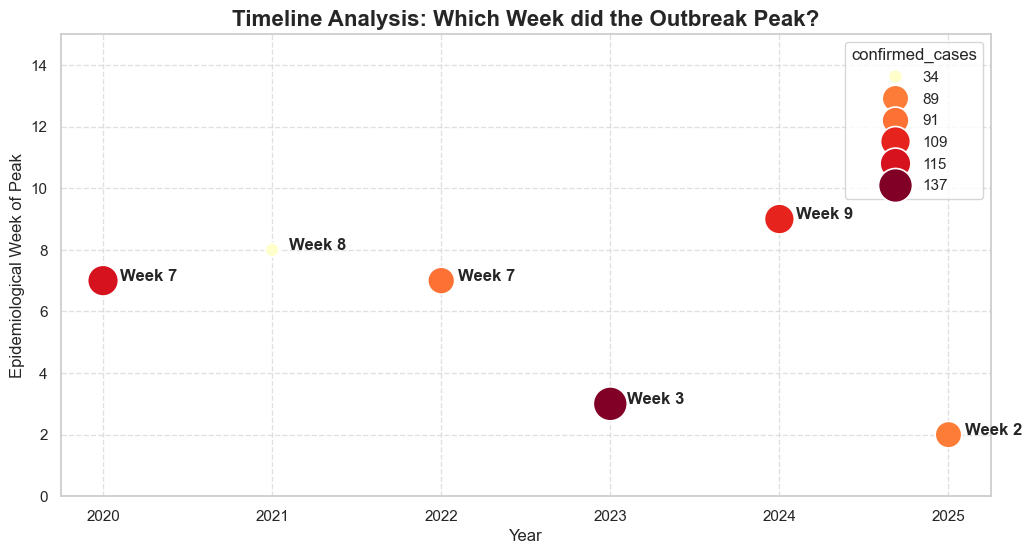

--- Peak Week Analysis ---
     epi_year  epi_week  confirmed_cases
6        2020         7              115
60       2021         8               34
111      2022         7               91
159      2023         3              137
217      2024         9              109
262      2025         2               89


In [31]:
# 2. Categorize data into two time periods for comparison
# This helps us see if the "Old Norm" is different from the "New Norm"
df['period'] = df['epi_year'].apply(lambda x: 'Early (2020-2022)' if x <= 2022 else 'Recent (2023-2025)')

# 3. Calculate average cases by week for each period
period_seasonality = df.groupby(['period', 'epi_week'])['confirmed_cases'].mean().reset_index()

# 4. Identify the Peak Week for every single year to find outliers
peak_weeks = df.loc[df.groupby('epi_year')['confirmed_cases'].idxmax()][['epi_year', 'epi_week', 'confirmed_cases']]

# --- VISUALIZATION A: THE SEASONAL SHIFT ---
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

sns.lineplot(data=period_seasonality, x='epi_week', y='confirmed_cases', 
             hue='period', palette=['#1f77b4', '#d62728'], linewidth=3.5)

plt.title('Is the Lassa Season Moving? Early (2020-22) vs. Recent (2023-25)', fontsize=16, fontweight='bold')
plt.xlabel('Epidemiological Week', fontsize=12)
plt.ylabel('Average Confirmed Cases', fontsize=12)
plt.axvspan(1, 10, color='grey', alpha=0.1, label='Traditional High-Season')
plt.legend(title="Time Period")
plt.tight_layout()
plt.show()

# --- VISUALIZATION B: PEAK WEEK TRACKER ---
plt.figure(figsize=(12, 6))
# We plot the week of the peak for each year. 
# A downward trend in dots means the outbreak is arriving EARLIER.
sns.scatterplot(data=peak_weeks, x='epi_year', y='epi_week', 
                size='confirmed_cases', hue='confirmed_cases', 
                palette='YlOrRd', sizes=(100, 600))

# Add labels to the dots
for i in range(peak_weeks.shape[0]):
    plt.text(peak_weeks.epi_year.iloc[i]+0.1, peak_weeks.epi_week.iloc[i], 
             f"Week {int(peak_weeks.epi_week.iloc[i])}", weight='bold')

plt.title('Timeline Analysis: Which Week did the Outbreak Peak?', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Epidemiological Week of Peak', fontsize=12)
plt.ylim(0, 15) # Zoom in on the early part of the year
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 5. Output the results for the report
print("--- Peak Week Analysis ---")
print(peak_weeks.sort_values('epi_year'))

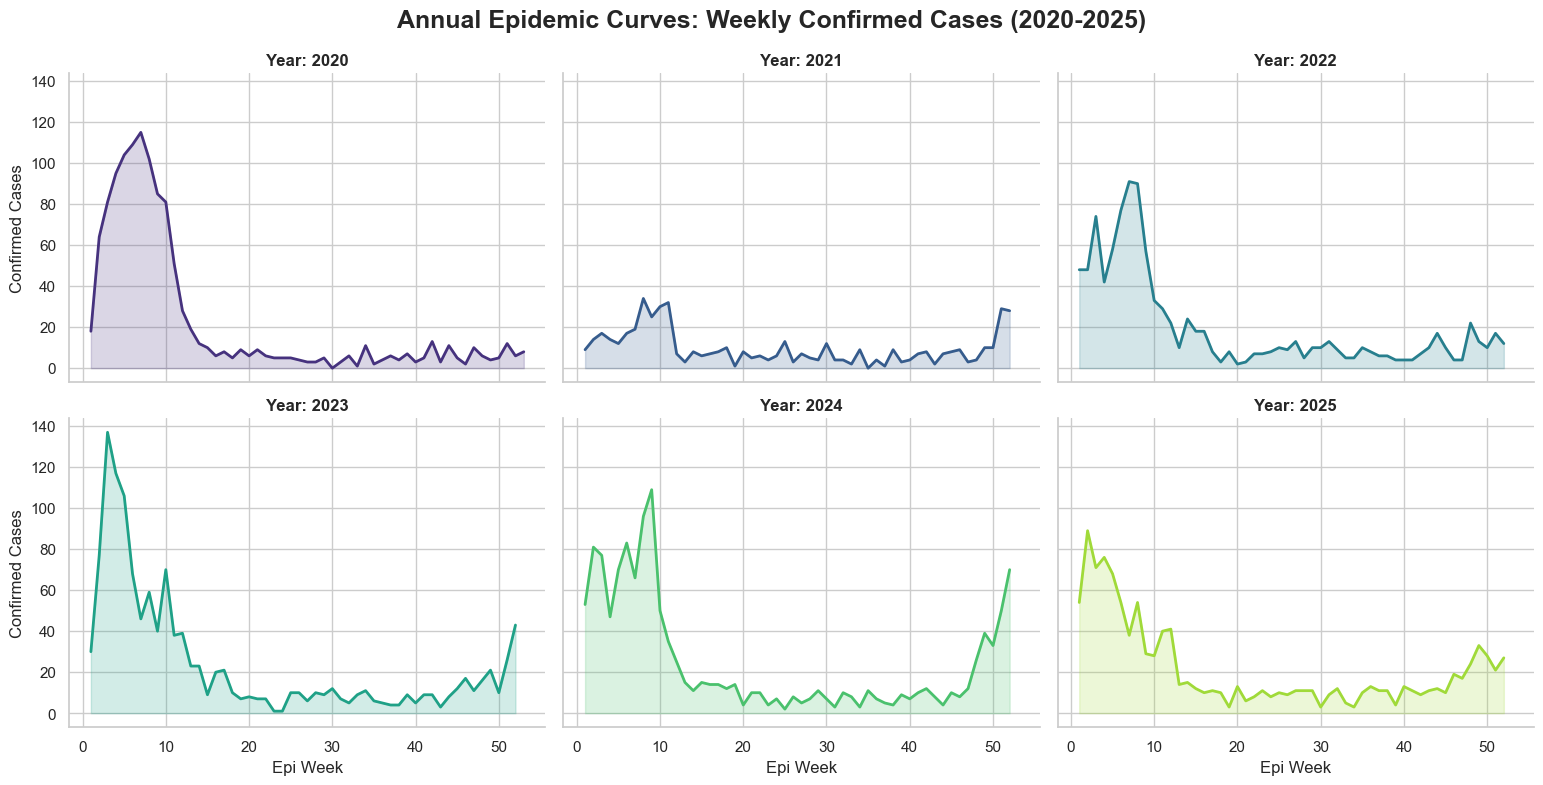

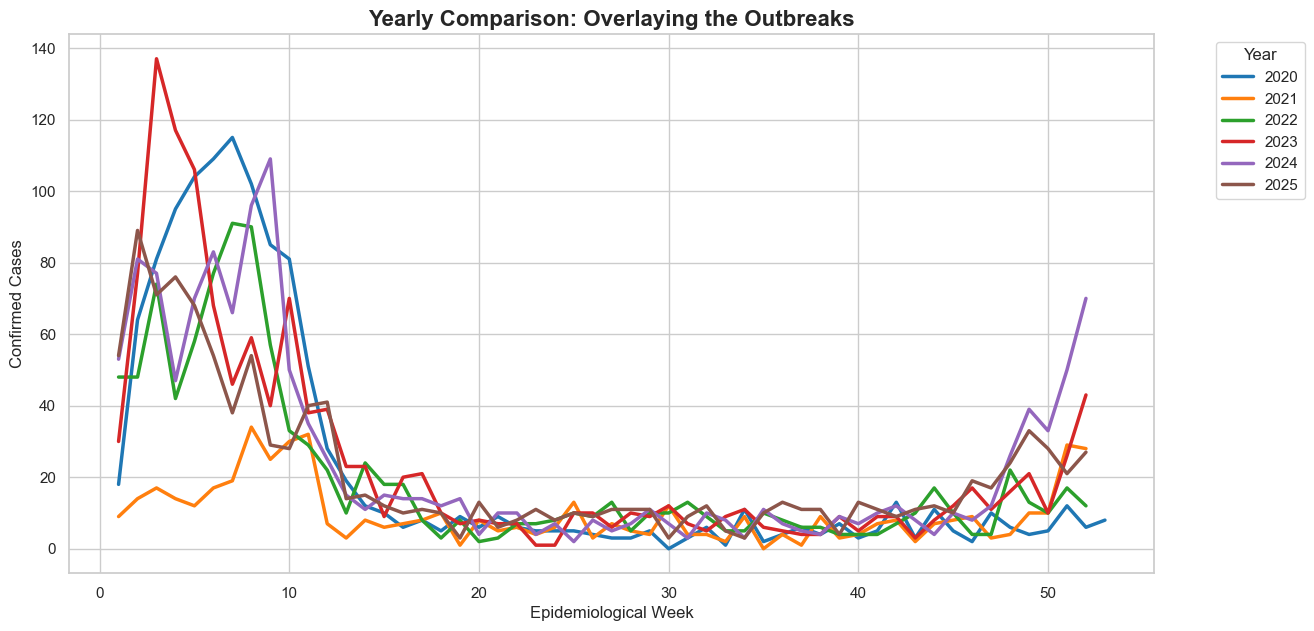

   epi_year  total_cases  peak_cases
0      2020         1190         115
1      2021          511          34
2      2022         1042          91
3      2023         1271         137
4      2024         1311         109
5      2025         1131          89


In [32]:
# 2. Style and Faceted Plot
sns.set_theme(style="whitegrid")
g = sns.FacetGrid(df, col="epi_year", col_wrap=3, height=4, aspect=1.3, hue="epi_year", palette="viridis")
g.map(plt.plot, "epi_week", "confirmed_cases", linewidth=2)
g.map(plt.fill_between, "epi_week", "confirmed_cases", alpha=0.2)

g.set_axis_labels("Epi Week", "Confirmed Cases")
g.set_titles("Year: {col_name}", fontweight='bold')
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Annual Epidemic Curves: Weekly Confirmed Cases (2020-2025)', fontsize=18, fontweight='bold')
plt.show()

# 3. Overlaid Plot for the "Worst Year" Comparison
plt.figure(figsize=(14, 7))
sns.lineplot(data=df, x='epi_week', y='confirmed_cases', hue='epi_year', palette='tab10', linewidth=2.5)
plt.title('Yearly Comparison: Overlaying the Outbreaks', fontsize=16, fontweight='bold')
plt.xlabel('Epidemiological Week')
plt.ylabel('Confirmed Cases')
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# 4. Critical Metrics for your Report
annual_summary = df.groupby('epi_year').agg(
    total_cases=('confirmed_cases', 'sum'),
    peak_cases=('confirmed_cases', 'max')
).reset_index()
print(annual_summary)

/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/741496471.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='epi_year', y='probable_cases', estimator=sum, palette='Greens', ax=axes[0])
/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/741496471.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=extraction_impact, x='extraction_method', y='suspected_cases', palette='Blues', ax=axes[1])


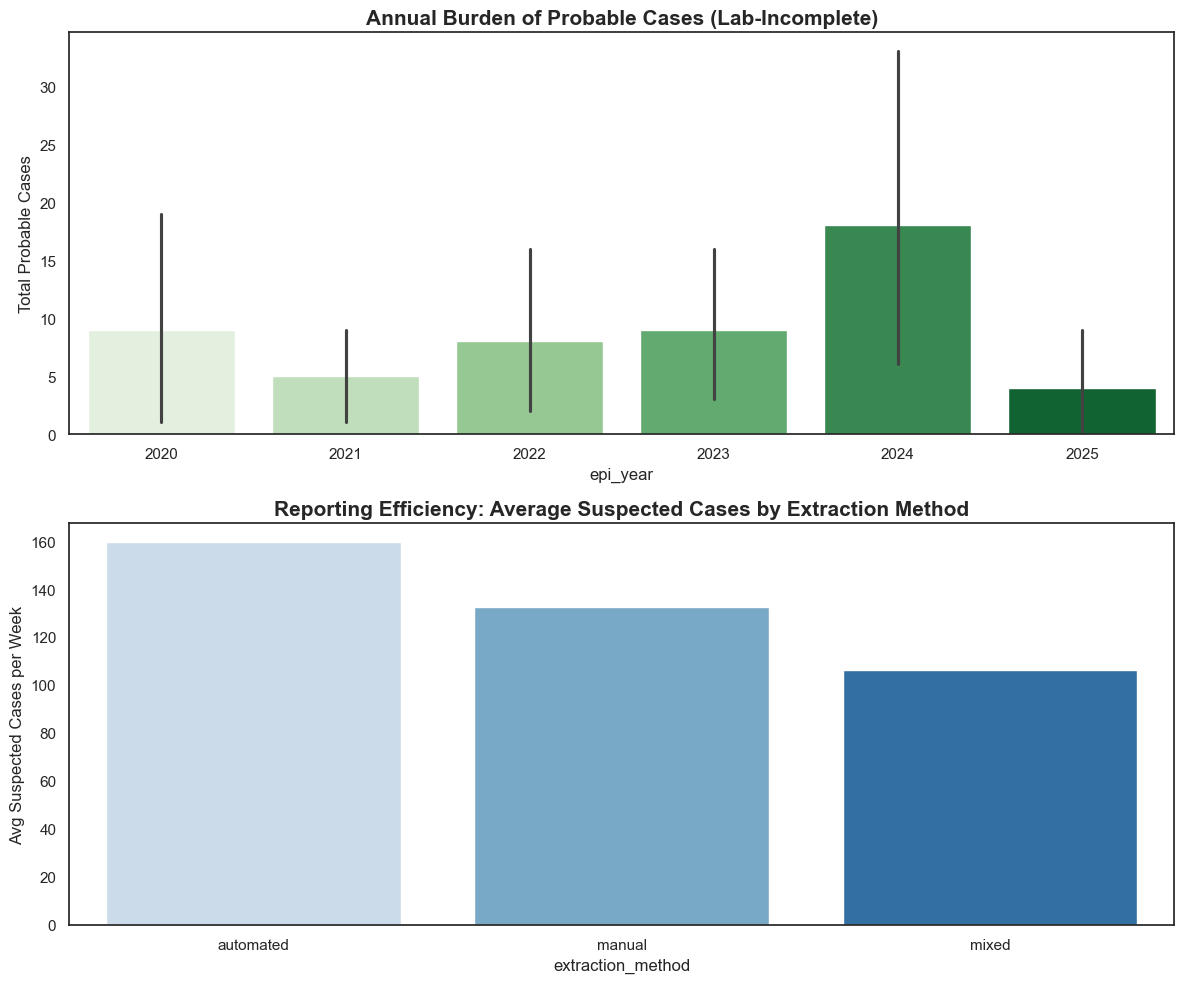

In [33]:
# 2. Analyze Extraction Method (Efficiency of Reporting)
# We want to see if 'Automated' extraction catches more than 'Manual'
extraction_impact = df.groupby('extraction_method').agg({
    'suspected_cases': 'mean',
    'confirmed_cases': 'mean'
}).reset_index()

# 3. Visualization: The Quality Dashboard
sns.set_theme(style="white")
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# --- Plot A: Probable Cases Trend ---
sns.barplot(data=df, x='epi_year', y='probable_cases', estimator=sum, palette='Greens', ax=axes[0])
axes[0].set_title('Annual Burden of Probable Cases (Lab-Incomplete)', fontsize=15, fontweight='bold')
axes[0].set_ylabel('Total Probable Cases')

# --- Plot B: Extraction Method vs Data Volume ---
sns.barplot(data=extraction_impact, x='extraction_method', y='suspected_cases', palette='Blues', ax=axes[1])
axes[1].set_title('Reporting Efficiency: Average Suspected Cases by Extraction Method', fontsize=15, fontweight='bold')
axes[1].set_ylabel('Avg Suspected Cases per Week')

plt.tight_layout()
plt.show()

/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/3657692177.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lags, y=corrs, palette='Reds_d')


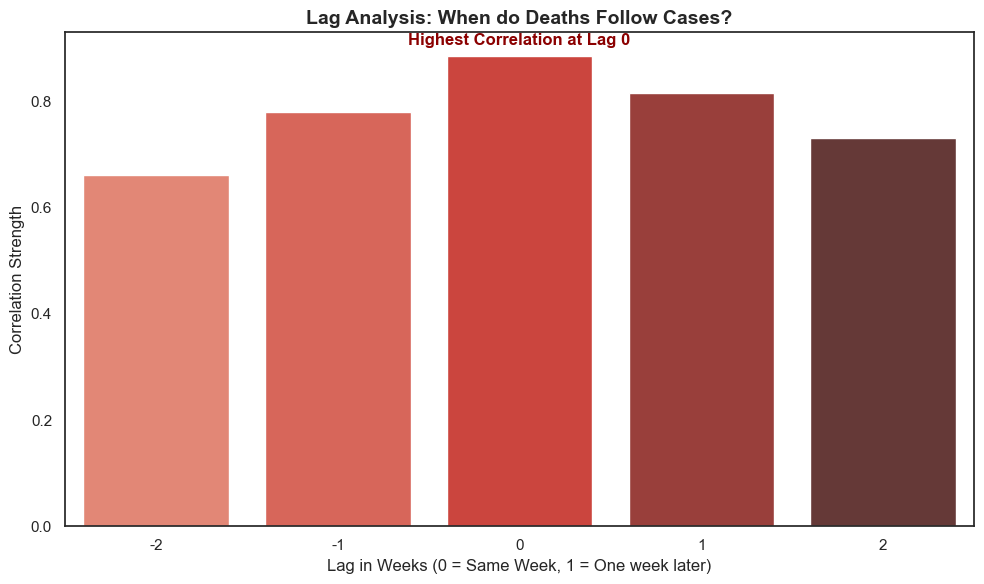

In [34]:
# Calculate correlation for different lags (-2 to +2 weeks)
lags = [-2, -1, 0, 1, 2]
corrs = [df['confirmed_cases'].corr(df['deaths'].shift(-l)) for l in lags]

# Visualization
plt.figure(figsize=(10, 6))
sns.barplot(x=lags, y=corrs, palette='Reds_d')
plt.title('Lag Analysis: When do Deaths Follow Cases?', fontsize=14, fontweight='bold')
plt.xlabel('Lag in Weeks (0 = Same Week, 1 = One week later)')
plt.ylabel('Correlation Strength')

# Annotate the highest bar
plt.text(2, corrs[2] + 0.02, 'Highest Correlation at Lag 0', ha='center', fontweight='bold', color='darkred')

plt.tight_layout()
plt.show()

/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/3782537592.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lags, y=corrs, palette='viridis')


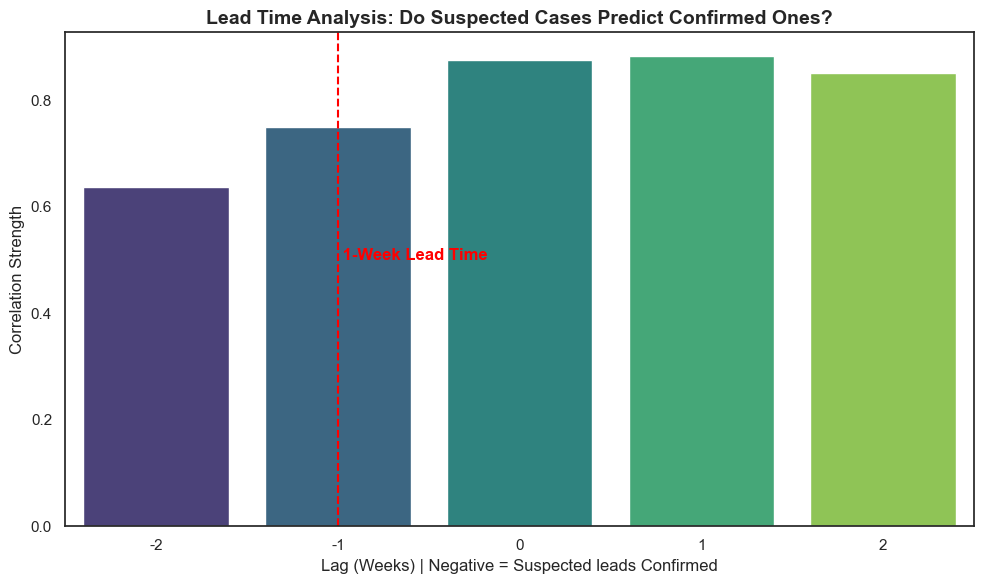

In [35]:
# Calculate correlations for lags (from -2 to +2 weeks)
# A negative lag here means Suspected leads Confirmed
lags = [-2, -1, 0, 1, 2]
corrs = [df['suspected_cases'].corr(df['confirmed_cases'].shift(l)) for l in lags]

# Visualization
plt.figure(figsize=(10, 6))
sns.barplot(x=lags, y=corrs, palette='viridis')
plt.title('Lead Time Analysis: Do Suspected Cases Predict Confirmed Ones?', fontsize=14, fontweight='bold')
plt.xlabel('Lag (Weeks) | Negative = Suspected leads Confirmed')
plt.ylabel('Correlation Strength')

# Highlight the -1 Week Lead
plt.axvline(x=1, color='red', linestyle='--') # index 1 corresponds to lag -1
plt.text(1, 0.5, ' 1-Week Lead Time', color='red', fontweight='bold')

plt.tight_layout()
plt.show()

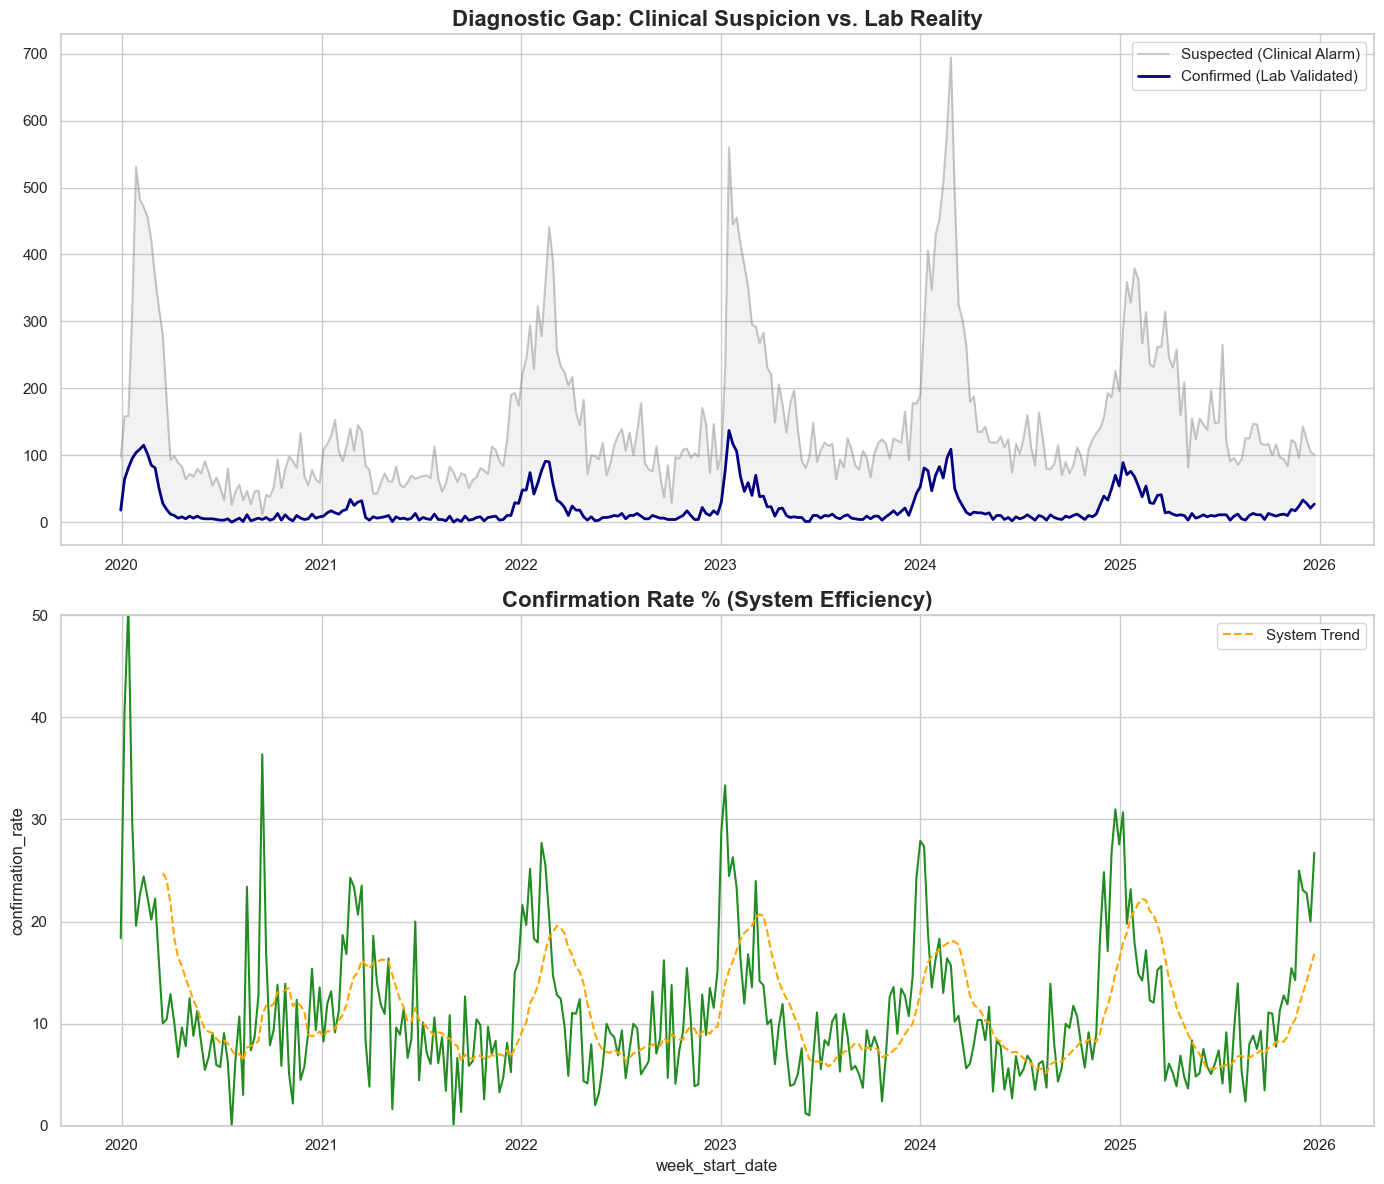

In [36]:
# 2. Calculate the Efficiency Metric
df['confirmation_rate'] = (df['confirmed_cases'] / df['suspected_cases']).fillna(0) * 100

# 3. Visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- Plot A: The Diagnostic Gap ---
# This visualizes the 'Funnel' as a time-series gap
axes[0].plot(df['week_start_date'], df['suspected_cases'], label='Suspected (Clinical Alarm)', color='gray', alpha=0.4)
axes[0].plot(df['week_start_date'], df['confirmed_cases'], label='Confirmed (Lab Validated)', color='navy', linewidth=2)
axes[0].fill_between(df['week_start_date'], df['confirmed_cases'], df['suspected_cases'], color='gray', alpha=0.1)
axes[0].set_title('Diagnostic Gap: Clinical Suspicion vs. Lab Reality', fontsize=16, fontweight='bold')
axes[0].legend()

# --- Plot B: Confirmation Rate Trend ---
# Does the line go up (better labs) or down (over-reporting)?
sns.lineplot(data=df, x='week_start_date', y='confirmation_rate', ax=axes[1], color='forestgreen')
# 12-week smoothing helps us see long-term system changes
df['smooth_rate'] = df['confirmation_rate'].rolling(window=12).mean()
axes[1].plot(df['week_start_date'], df['smooth_rate'], color='orange', linestyle='--', label='System Trend')

axes[1].set_title('Confirmation Rate % (System Efficiency)', fontsize=16, fontweight='bold')
axes[1].set_ylim(0, 50) # Focused range
axes[1].legend()

plt.tight_layout()
plt.show()

/var/folders/tr/jb5rcznx5cx_5ggz3m54mxsm0000gn/T/ipykernel_26815/546580368.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=annual_stats, x='epi_year', y='gap_ratio_pct', palette='Greens_r', ax=axes[1])


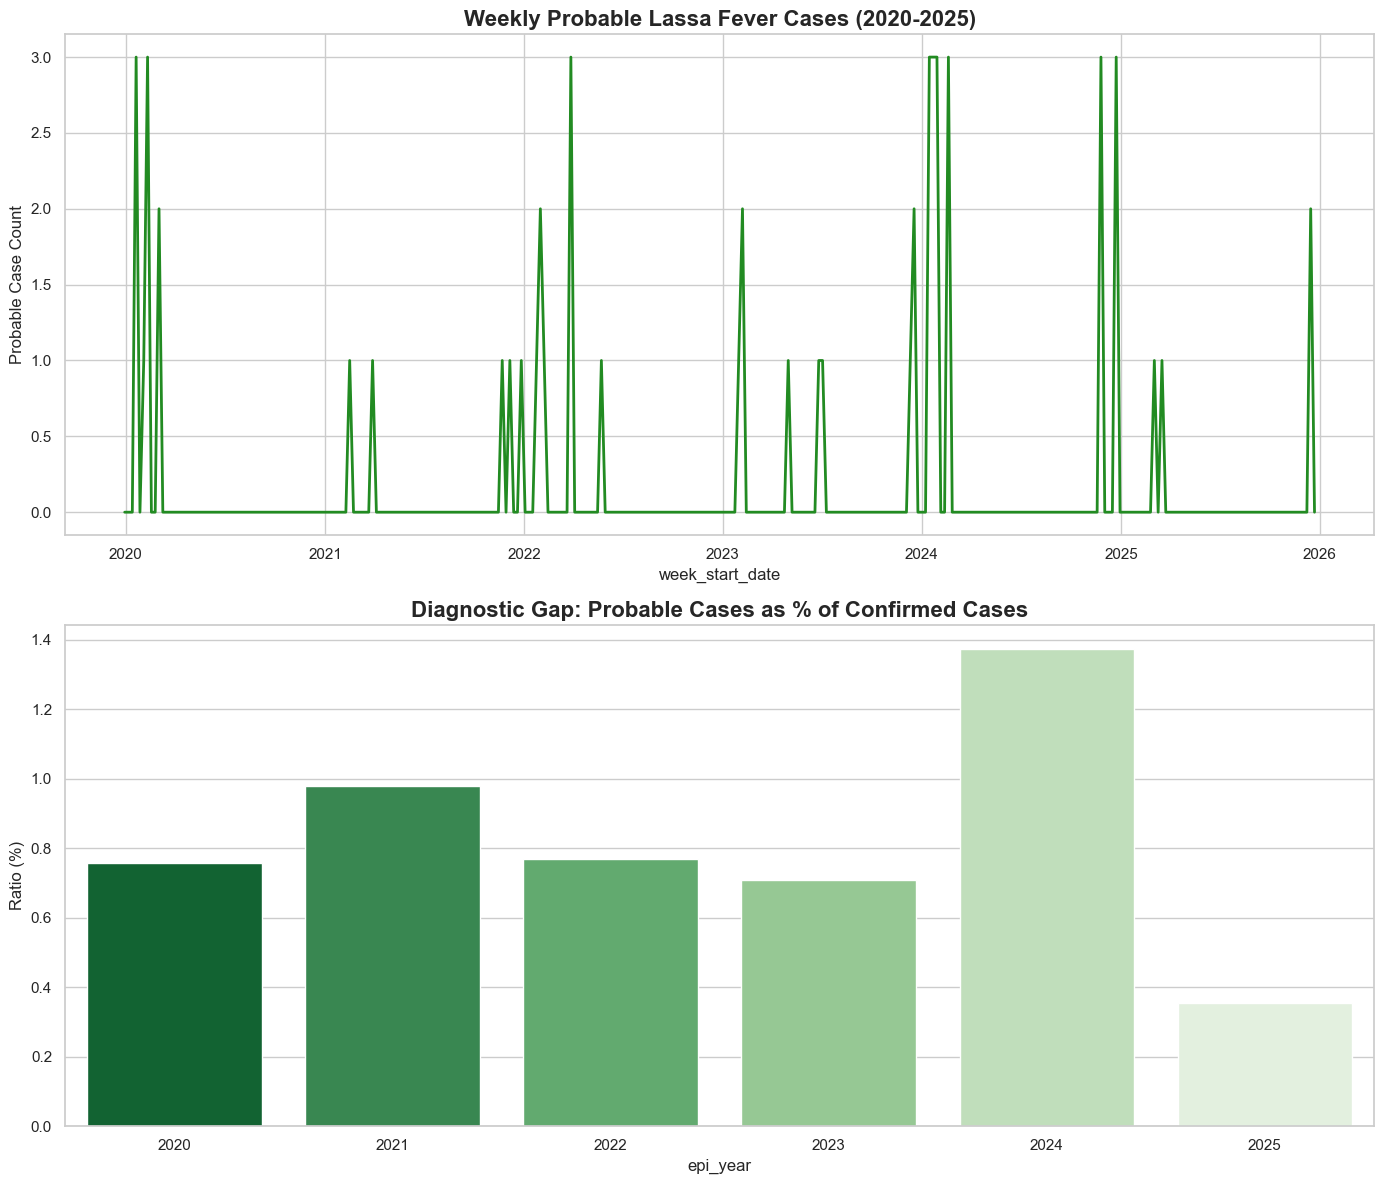

In [37]:
# 2. Calculate the Diagnostic Gap Ratio
annual_stats = df.groupby('epi_year').agg({
    'probable_cases': 'sum',
    'confirmed_cases': 'sum'
}).reset_index()
annual_stats['gap_ratio_pct'] = (annual_stats['probable_cases'] / annual_stats['confirmed_cases']) * 100

# 3. Visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- Plot A: Probable Cases Over Time ---
sns.lineplot(data=df, x='week_start_date', y='probable_cases', ax=axes[0], color='forestgreen', linewidth=2)
axes[0].set_title('Weekly Probable Lassa Fever Cases (2020-2025)', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Probable Case Count')

# --- Plot B: Probable vs Confirmed Ratio ---
sns.barplot(data=annual_stats, x='epi_year', y='gap_ratio_pct', palette='Greens_r', ax=axes[1])
axes[1].set_title('Diagnostic Gap: Probable Cases as % of Confirmed Cases', fontsize=16, fontweight='bold')
axes[1].set_ylabel('Ratio (%)')

plt.tight_layout()
plt.show()

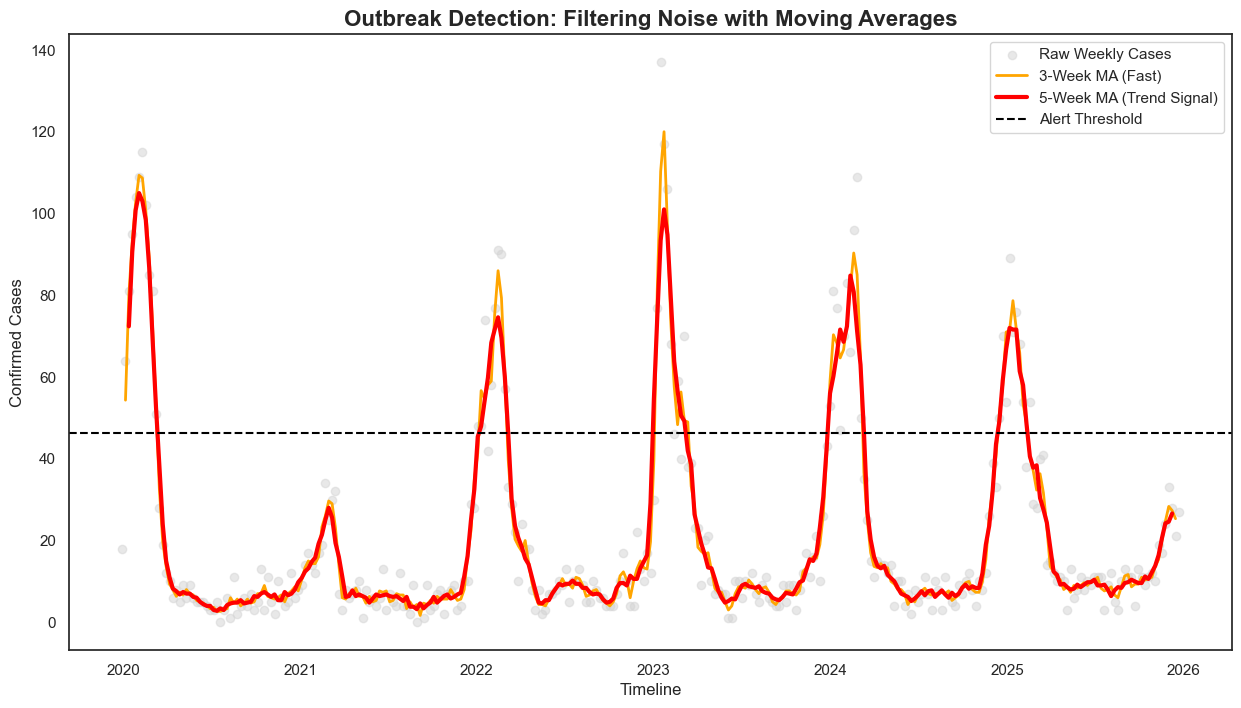

In [38]:
# 2. Calculate Moving Averages
# 'center=True' aligns the average with the middle of the window
df['ma_3'] = df['confirmed_cases'].rolling(window=3, center=True).mean()
df['ma_5'] = df['confirmed_cases'].rolling(window=5, center=True).mean()

# 3. Visualization
plt.figure(figsize=(15, 8))
sns.set_theme(style="white")

# Plot Raw Data as light grey dots
plt.scatter(df['week_start_date'], df['confirmed_cases'], color='lightgrey', alpha=0.5, label='Raw Weekly Cases')

# Plot the Moving Averages
plt.plot(df['week_start_date'], df['ma_3'], color='orange', linewidth=2, label='3-Week MA (Fast)')
plt.plot(df['week_start_date'], df['ma_5'], color='red', linewidth=3, label='5-Week MA (Trend Signal)')

# Add an "Alert Threshold" (Standard Deviation above mean)
threshold = df['confirmed_cases'].mean() + (df['confirmed_cases'].std())
plt.axhline(y=threshold, color='black', linestyle='--', label='Alert Threshold')

plt.title('Outbreak Detection: Filtering Noise with Moving Averages', fontsize=16, fontweight='bold')
plt.xlabel('Timeline')
plt.ylabel('Confirmed Cases')
plt.legend()
plt.show()

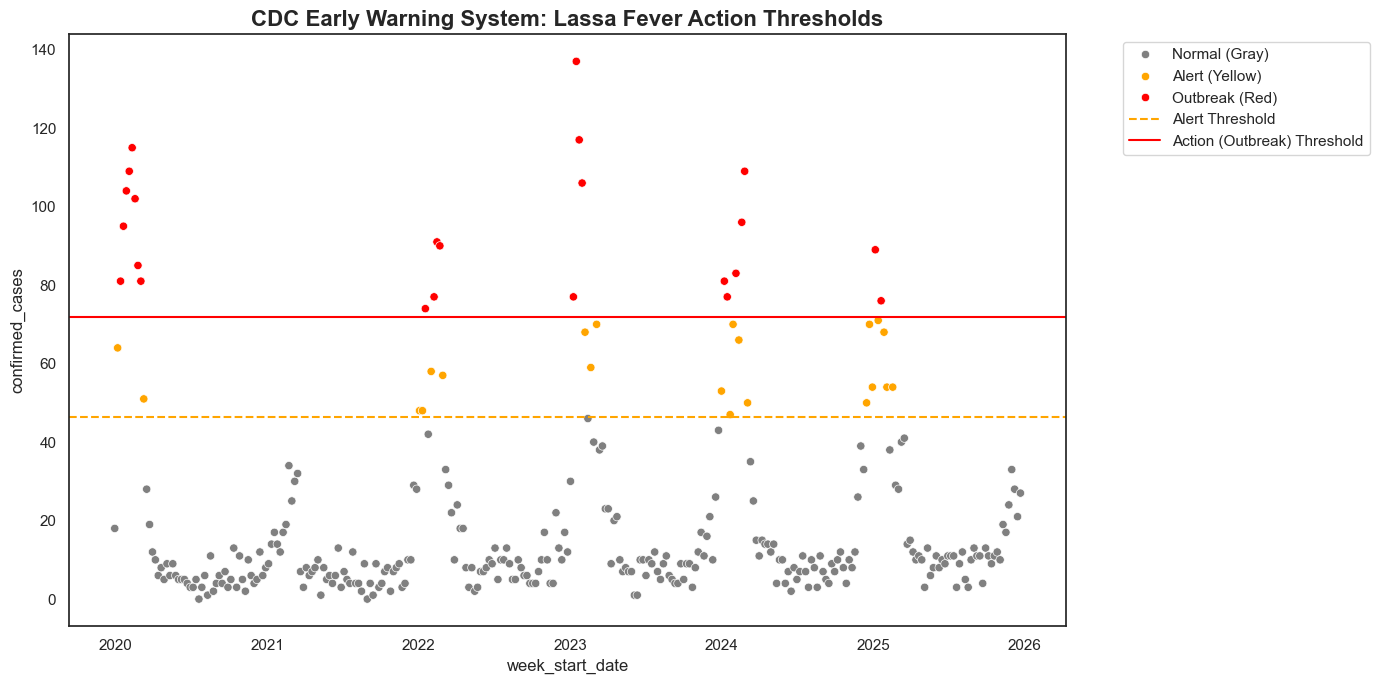

In [39]:
# 2. Calculate thresholds based on historical standard deviation
mean_val = df['confirmed_cases'].mean()
std_val = df['confirmed_cases'].std()

alert_limit = mean_val + std_val
action_limit = mean_val + (2 * std_val)

# 3. Tag the weeks
def categorize(cases):
    if cases > action_limit: return 'Outbreak (Red)'
    if cases > alert_limit: return 'Alert (Yellow)'
    return 'Normal (Gray)'

df['status'] = df['confirmed_cases'].apply(categorize)

# 4. Visualization
plt.figure(figsize=(14, 7))
sns.scatterplot(data=df, x='week_start_date', y='confirmed_cases', hue='status', 
                palette={'Normal (Gray)': 'gray', 'Alert (Yellow)': 'orange', 'Outbreak (Red)': 'red'})

plt.axhline(alert_limit, color='orange', linestyle='--', label='Alert Threshold')
plt.axhline(action_limit, color='red', linestyle='-', label='Action (Outbreak) Threshold')

plt.title('CDC Early Warning System: Lassa Fever Action Thresholds', fontsize=16, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

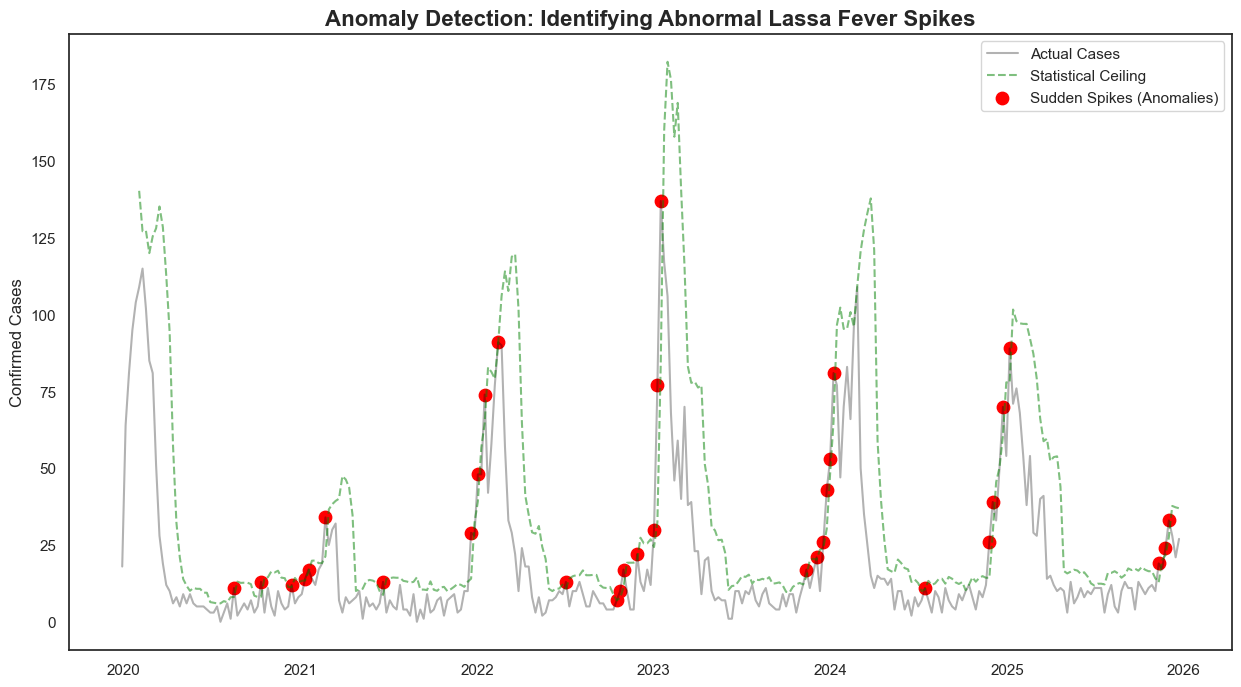

    week_start_date  epi_year  epi_week  confirmed_cases
209      2024-01-01      2024         1               53
210      2024-01-08      2024         2               81
237      2024-07-15      2024        29               11
256      2024-11-25      2024        48               26
257      2024-12-02      2024        49               39
260      2024-12-23      2024        52               70
262      2025-01-06      2025         2               89
306      2025-11-10      2025        46               19
308      2025-11-24      2025        48               24
309      2025-12-01      2025        49               33


In [40]:
# 2. CALCULATE THE "CEILING" (Rolling Anomaly Detection)
# We compare each week to the average of the previous 5 weeks
window = 5
df['roll_mean'] = df['confirmed_cases'].shift(1).rolling(window=window).mean()
df['roll_std'] = df['confirmed_cases'].shift(1).rolling(window=window).std()

# Threshold: Mean + 2 Standard Deviations
df['ceiling'] = df['roll_mean'] + (2 * df['roll_std'])

# Tag as Anomaly if it breaks the ceiling (and is more than 5 cases to avoid noise)
df['is_anomaly'] = (df['confirmed_cases'] > df['ceiling']) & (df['confirmed_cases'] > 5)

# 3. VISUALIZATION
plt.figure(figsize=(15, 8))
sns.set_theme(style="white")

# Plot the trend and the ceiling
plt.plot(df['week_start_date'], df['confirmed_cases'], color='black', alpha=0.3, label='Actual Cases')
plt.plot(df['week_start_date'], df['ceiling'], color='green', linestyle='--', alpha=0.5, label='Statistical Ceiling')

# Highlight Anomaly Points in Red
anomalies = df[df['is_anomaly'] == True]
plt.scatter(anomalies['week_start_date'], anomalies['confirmed_cases'], color='red', s=80, label='Sudden Spikes (Anomalies)')

plt.title('Anomaly Detection: Identifying Abnormal Lassa Fever Spikes', fontsize=16, fontweight='bold')
plt.ylabel('Confirmed Cases')
plt.legend()
plt.show()

# 4. Print the "Red Alert" Weeks
print(df[df['is_anomaly'] == True][['week_start_date', 'epi_year', 'epi_week', 'confirmed_cases']].tail(10))

/opt/homebrew/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/opt/homebrew/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


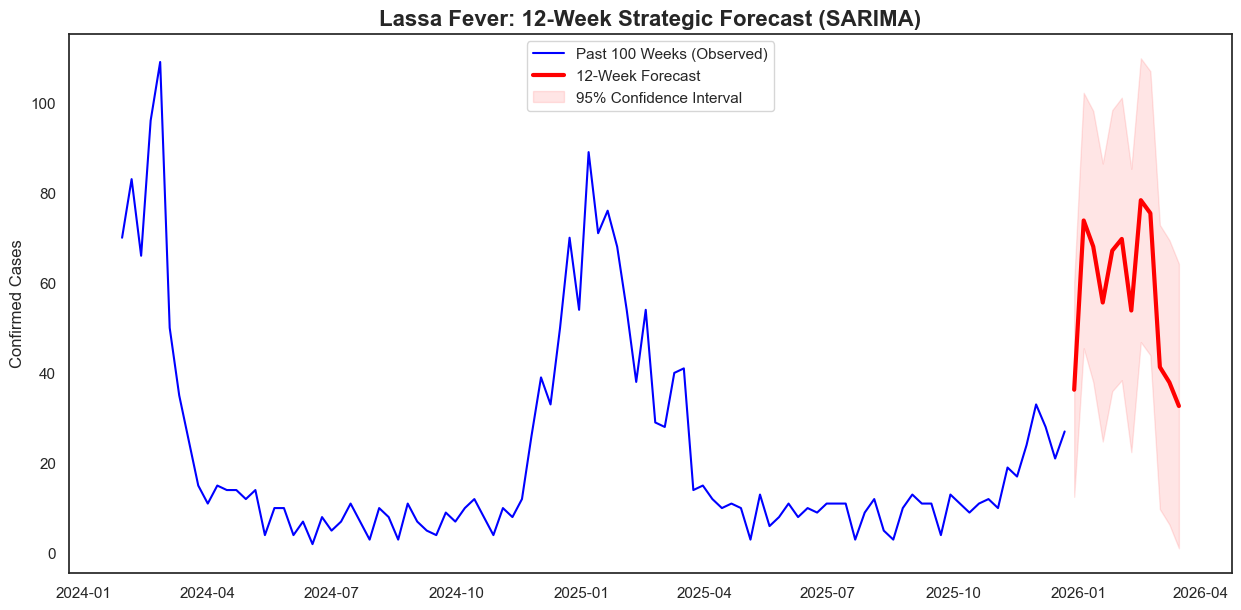

Predicted Peak Timing: 2026-02-16
Predicted Maximum Weekly Volume: 78.3 cases


In [47]:
ts = df.set_index('week_start_date')['confirmed_cases']

# 2. Build the SARIMA Model
# (1, 1, 1) x (1, 1, 0, 52) 
# The '52' tells the model to look at the yearly seasonal cycle.
model = SARIMAX(ts, order=(1, 1, 1), seasonal_order=(1, 1, 0, 52),
                enforce_stationarity=False, enforce_invertibility=False)
results = model.fit(disp=False)

# 3. Forecast the next 12 weeks
forecast_steps = 12
forecast = results.get_forecast(steps=forecast_steps)
forecast_df = forecast.summary_frame()

# Set dates for the forecast
forecast_index = pd.date_range(start=ts.index[-1] + pd.Timedelta(weeks=1), 
                               periods=forecast_steps, freq='W-MON')
forecast_df.index = forecast_index

# 4. Visualization
plt.figure(figsize=(15, 7))
plt.plot(ts.tail(100), label='Past 100 Weeks (Observed)', color='blue') # Tail for clarity
plt.plot(forecast_df['mean'], label='12-Week Forecast', color='red', linewidth=3)
plt.fill_between(forecast_df.index, forecast_df['mean_ci_lower'], 
                 forecast_df['mean_ci_upper'], color='red', alpha=0.1, label='95% Confidence Interval')

plt.title('Lassa Fever: 12-Week Strategic Forecast (SARIMA)', fontsize=16, fontweight='bold')
plt.ylabel('Confirmed Cases')
plt.legend()
plt.show()

# Print the predicted peak
print(f"Predicted Peak Timing: {forecast_df['mean'].idxmax().date()}")
print(f"Predicted Maximum Weekly Volume: {forecast_df['mean'].max():.1f} cases")

In [ ]:
# 4. Forecasting the next 12 weeks (Recursive)
model.eval()
preds = [x[0] for x in scaled_data[-seq_length:]]  # Flatten to list of floats

for _ in range(12):
    seq = torch.FloatTensor(preds[-seq_length:]).view(1, seq_length, 1)
    with torch.no_grad():
        preds.append(model(seq).item())

# Inverse scale to get actual case numbers
forecast = scaler.inverse_transform(np.array(preds[seq_length:]).reshape(-1, 1))

# 5. Visualization
plt.figure(figsize=(12, 6))
plt.plot(range(len(data)), data, label='Historical Data')
plt.plot(range(len(data), len(data) + 12), forecast, label='PyTorch LSTM Forecast', color='red', marker='o')
plt.title('Lassa Fever: Advanced PyTorch LSTM Forecast')
plt.legend()
plt.show()

Epoch 0 loss: 0.03727802
Epoch 20 loss: 0.02416717
Epoch 40 loss: 0.01810910
Epoch 60 loss: 0.01220435
Epoch 80 loss: 0.01029117


TypeError: not a sequence